# CS688 Homework 3

## Goal

Clustering on Indiegogo campaign titles.

- 10 CSV files
- bag of words on titles
- 3 text cleaning steps
- TF-IDF, LSA, and LDA
- dendrogram


## Setup

- Uncomment the cell below if you need to install packages.
- The next code cell loads those libraries and sets the random seed.
- Download the 10 CSV files from 2025 at https://webrobots.io/indiegogo-dataset/ (assignment minimum is 5). Use the CSV links, not JSON.
- Each monthly zip unpacks to the same filename. Rename them as you go so they do not overwrite each other.
- Put the CSVs in `data/` next to this notebook:

```shell
data/
  Indiegogo-part1.csv
  Indiegogo-part2.csv
  Indiegogo-part3.csv
  Indiegogo-part4.csv
  Indiegogo-part5.csv
  Indiegogo-part6.csv
  Indiegogo-part7.csv
  Indiegogo-part8.csv
  Indiegogo-part9.csv
  Indiegogo-part10.csv
```

The load cell reads every `*.csv` in `data/`.

In [104]:
pip install numpy pandas scipy matplotlib scikit-learn nltk

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [105]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.cluster import AgglomerativeClustering

RANDOM_STATE = 42  # same seed so LSA and LDA come out the same each run
TOKEN_PATTERN = r'(?u)\b[a-zA-Z]{2,}\b'  # keep letter tokens of 2+ characters; drop digits and one-letter junk


## Data

Used 10 CSV files from the Indiegogo data set and then we print the columns so we can pick the title field.


In [106]:
csv_files = sorted(Path('data').glob('*.csv'))

frames = []
for path in csv_files:
    frame = pd.read_csv(path, low_memory=False)
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True)
print('files:', len(csv_files))
print('rows:', len(raw))
print('columns:', raw.columns.tolist())
raw.head(3)


files: 10
rows: 254822
columns: ['bullet_point', 'category', 'category_url', 'clickthrough_url', 'close_date', 'currency', 'funds_raised_amount', 'funds_raised_percent', 'image_url', 'is_indemand', 'is_pre_launch', 'is_promoted', 'is_proven', 'offered_by', 'open_date', 'perk_goal_percentage', 'perks_claimed', 'price_offered', 'price_retail', 'product_stage', 'project_id', 'project_type', 'source_url', 'tagline', 'tags', 'title']


,bullet_point,category,category_url,clickthrough_url,close_date,currency,funds_raised_amount,funds_raised_percent,image_url,is_indemand,...,perks_claimed,price_offered,price_retail,product_stage,project_id,project_type,source_url,tagline,tags,title
0,https://usukmarket.com/product/buy-new-old-gmail-accounts/,"Podcasts, Blogs & Vlogs",/explore/podcasts-blogs-vlogs,/projects/--3045209/coming_soon,NaN,FAKE_CURRENCY,0,0.0,"https://c1.iggcdn.com/indiegogo-media-prod-cld/image/upload/c_fill,f_auto,h_273,w_273/jindais2ti4zlhfdstt8.jpg",False,...,NaN,NaN,NaN,NaN,3109791,campaign,https://www.indiegogo.com/explore/all?project_timing=all&product_stage=all&ended_campaigns_included=false&sort=trending,"@ Buy Gmail Account, buy Indian Gmail accounts, Buy New & Old Gmail Accounts,",NaN,"Buy New & Old Gmail Accounts, From usukmarket"
1,https://sellsusa.com/product/buy-linkedin-accounts/,"Podcasts, Blogs & Vlogs",/explore/podcasts-blogs-vlogs,/projects/--3093373/coming_soon,NaN,FAKE_CURRENCY,0,0.0,"https://c1.iggcdn.com/indiegogo-media-prod-cld/image/upload/c_fill,f_auto,h_273,w_273/vgt2xmmrz2ynfle7fo8l.jpg",False,...,NaN,NaN,NaN,NaN,3158193,campaign,https://www.indiegogo.com/explore/all?project_timing=all&product_stage=all&ended_campaigns_included=false&sort=trending,WhatsApp:- +1 (606) 264-0854\nEmail:sellsusa2@gmail.com\nTelegram:- @sellsusa\nSkype: sellsusa,NaN,How to Buy a LinkedIn Account Safely
2,➤➤Telegram: @Smmpvashop ➤➤WhatsApp: ‪+1 (740)403-5962,"Podcasts, Blogs & Vlogs",/explore/podcasts-blogs-vlogs,/projects/--3033312/coming_soon,NaN,FAKE_CURRENCY,0,0.0,"https://c1.iggcdn.com/indiegogo-media-prod-cld/image/upload/c_fill,f_auto,h_273,w_273/boneyhqmhnbty7442cwy.jpg",False,...,NaN,NaN,NaN,NaN,3097827,campaign,https://www.indiegogo.com/explore/all?project_timing=all&product_stage=all&ended_campaigns_included=false&sort=trending,#wise #wisdom #love #wisewords #quotes #life #motivation #wordsofwisdom #quote #knowledge #wisdomqu,NaN,"kiss Time Buy, Verified Wise Accounts"


## Extract Titles

Next we extract our title data. We also drop empty rows and exact duplicates.


In [107]:
# keep the title column
titles = raw[['title']].copy()
titles = titles.rename(columns={'title': 'raw_title'})
titles['raw_title'] = titles['raw_title'].astype(str).str.strip()

# drop blanks and exact duplicate titles
titles = titles[titles['raw_title'] != '']
titles = titles[titles['raw_title'].str.lower() != 'nan']
titles = titles.drop_duplicates(subset=['raw_title']).reset_index(drop=True)

print('unique titles:', len(titles))
pd.set_option('display.max_colwidth', 120)  # show more of each title in the tables below
titles.head(10)


unique titles: 21750


,raw_title
0,"Buy New & Old Gmail Accounts, From usukmarket"
1,How to Buy a LinkedIn Account Safely
2,"kiss Time Buy, Verified Wise Accounts"
3,Affordable Negative Google Reviews for Sale!
4,Buy Amazon Accounts - - SMM USA World
5,"Most 10 Sites To Buy Linkedin Accounts Aged, New"
6,86buy facebook accounts - United Kingdom
7,12 Best Site to Buy Old Instagram Accounts
8,Buy Gmail Accounts
9,"Top 2To Buy Airbnb Account (Parsonal & Super""Host)"


## Feature engineering

1. Lowercase; drop URLs, digits, and punctuation
2. Remove stop words
3. Stem with SnowballStemmer


In [108]:
from nltk.stem import SnowballStemmer

stemmer = SnowballStemmer('english')
stop_words = set(ENGLISH_STOP_WORDS)

def normalize_text(text):
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def remove_stopwords(text):
    kept = []
    for token in text.split():
        if token not in stop_words and len(token) > 1:
            kept.append(token)
    return ' '.join(kept)

def stem_text(text):
    return ' '.join(stemmer.stem(token) for token in text.split())

titles['normalized_title'] = titles['raw_title'].map(normalize_text)
titles['stopword_removed_title'] = titles['normalized_title'].map(remove_stopwords)
titles['stemmed_title'] = titles['stopword_removed_title'].map(stem_text)
titles = titles[titles['stemmed_title'].str.len() > 0].reset_index(drop=True)

display(titles[['raw_title', 'normalized_title', 'stopword_removed_title', 'stemmed_title']].head(12))

# bag of words after each cleaning step, so we can see if the matrix got smaller
rows = []
for name, column in [
    ('Raw titles', 'raw_title'),
    ('After normalization', 'normalized_title'),
    ('After stop words', 'stopword_removed_title'),
    ('After stemming', 'stemmed_title'),
]:
    X = CountVectorizer(token_pattern=TOKEN_PATTERN).fit_transform(titles[column])
    n_docs, n_terms = X.shape
    density = X.nnz / (n_docs * n_terms)
    rows.append({
        'Step': name,
        'Titles': n_docs,
        'Terms': n_terms,
        'Nonzero': X.nnz,
        'Sparsity': f'{1 - density:.4%}',
    })
pd.DataFrame(rows)


,raw_title,normalized_title,stopword_removed_title,stemmed_title
0,"Buy New & Old Gmail Accounts, From usukmarket",buy new old gmail accounts from usukmarket,buy new old gmail accounts usukmarket,buy new old gmail account usukmarket
1,How to Buy a LinkedIn Account Safely,how to buy a linkedin account safely,buy linkedin account safely,buy linkedin account safe
2,"kiss Time Buy, Verified Wise Accounts",kiss time buy verified wise accounts,kiss time buy verified wise accounts,kiss time buy verifi wise account
3,Affordable Negative Google Reviews for Sale!,affordable negative google reviews for sale,affordable negative google reviews sale,afford negat googl review sale
4,Buy Amazon Accounts - - SMM USA World,buy amazon accounts smm usa world,buy amazon accounts smm usa world,buy amazon account smm usa world
5,"Most 10 Sites To Buy Linkedin Accounts Aged, New",most sites to buy linkedin accounts aged new,sites buy linkedin accounts aged new,site buy linkedin account age new
6,86buy facebook accounts - United Kingdom,buy facebook accounts united kingdom,buy facebook accounts united kingdom,buy facebook account unit kingdom
7,12 Best Site to Buy Old Instagram Accounts,best site to buy old instagram accounts,best site buy old instagram accounts,best site buy old instagram account
8,Buy Gmail Accounts,buy gmail accounts,buy gmail accounts,buy gmail account
9,"Top 2To Buy Airbnb Account (Parsonal & Super""Host)",top to buy airbnb account parsonal super host,buy airbnb account parsonal super host,buy airbnb account parson super host


,Step,Titles,Terms,Nonzero,Sparsity
0,Raw titles,20974,14740,124985,99.9596%
1,After normalization,20974,14993,126006,99.9599%
2,After stop words,20974,14763,100673,99.9675%
3,After stemming,20974,12371,100511,99.9613%


## Results of data cleaning

Start: 20,974 titles, 14,740 terms, 99.9596% sparse.

- Normalization split some hyphenated words, so the vocabulary went up a little (14,740 to 14,993). 
- Stop words cut nonzero cells from 126,006 to 100,673. 
- Stemming cut the vocabulary from 14,763 to 12,371. 
- Density went from 0.0404% to 0.0387%. 

Sparsity did not fall at every step. That is normal for short titles. The useful result is the smaller vocabulary I cluster on.


## TF-IDF

Same cleaned / stemmed titles as the count matrix.


In [109]:
# TF-IDF: same tokens as the later count matrix, but rare words get more weight
tfidf_vectorizer = TfidfVectorizer(token_pattern=TOKEN_PATTERN)
X_tfidf = tfidf_vectorizer.fit_transform(titles['stemmed_title'])

print('TF-IDF shape:', X_tfidf.shape)
print('nonzero:', X_tfidf.nnz)


TF-IDF shape: (20974, 12371)
nonzero: 100511


## LSA

Truncated SVD on the TF-IDF matrix. We try k = 2 through 8 with silhouette score, then name the clusters.


In [110]:
# LSA: shrink the TF-IDF matrix so we can cluster it
N_COMPONENTS = 20
lsa = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_lsa = lsa.fit_transform(X_tfidf)
print('explained variance:', f'{lsa.explained_variance_ratio_.sum():.2%}')

# try k = 2..8; higher silhouette = tighter, better-separated clusters
silhouette_rows = []
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_lsa)
    score = silhouette_score(X_lsa, labels)
    silhouette_rows.append({'k': k, 'silhouette': score})

silhouette_results = pd.DataFrame(silhouette_rows)
display(silhouette_results)

FINAL_K = int(silhouette_results.loc[silhouette_results['silhouette'].idxmax(), 'k'])
print('k with the highest silhouette:', FINAL_K)

# refit with that k
titles['lsa_cluster'] = AgglomerativeClustering(n_clusters=FINAL_K, linkage='ward').fit_predict(X_lsa)

# labels from reading the sampled titles
LSA_CLUSTER_NAMES = {
    0: 'mixed leftover titles',
    1: 'mixed verified-account sales',
    2: 'Cash App account sales',
    3: 'Gmail / PVA account sales',
    4: 'Dubai escort spam',
    5: 'Google Voice / review sales',
    6: 'LinkedIn account sales',
}

sizes = titles['lsa_cluster'].value_counts().sort_index().reset_index()
sizes.columns = ['cluster', 'n']
sizes['label'] = sizes['cluster'].map(LSA_CLUSTER_NAMES)
display(sizes)


explained variance: 20.30%


,k,silhouette
0,2,0.336683
1,3,0.367586
2,4,0.375014
3,5,0.390426
4,6,0.404271
5,7,0.411260
6,8,0.386957


k with the highest silhouette: 7


,cluster,n,label
0,0,11416,mixed leftover titles
1,1,4526,mixed verified-account sales
2,2,1523,Cash App account sales
3,3,1941,Gmail / PVA account sales
4,4,616,Dubai escort spam
5,5,524,Google Voice / review sales
6,6,428,LinkedIn account sales


### LSA results

20 components explained 20.30% of the variance. Silhouette was highest at k = 7 (0.411), so we used 7 clusters.

Most of the signal is account-sale words: account, buy, verified, cash, gmail, pva. There is also a Google-review group, a LinkedIn group, and a Dubai escort group. The two big clusters (11,416 leftovers and 4,526 mixed account sales) dominate. Cluster 0 is leftovers, not a real theme. The smaller clusters are repetitive, which is why they split cleanly.


## LDA

LDA on the count matrix. I look at the top words and how many titles landed in each topic.


In [111]:
# LDA wants raw word counts, not TF-IDF
count_vectorizer = CountVectorizer(token_pattern=TOKEN_PATTERN)
X_counts = count_vectorizer.fit_transform(titles['stemmed_title'])
count_terms = count_vectorizer.get_feature_names_out()

# five topics; each title gets a probability for each topic
N_TOPICS = 5
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    learning_method='batch',
    max_iter=30,
    random_state=RANDOM_STATE,
)
X_lda_topics = lda.fit_transform(X_counts)
titles['dominant_lda_topic'] = X_lda_topics.argmax(axis=1) + 1
titles['dominant_lda_probability'] = X_lda_topics.max(axis=1)

# top words per topic, plus how many titles landed there
rows = []
for i, weights in enumerate(lda.components_, start=1):
    top_idx = weights.argsort()[-10:][::-1]
    rows.append({
        'Topic': f'Topic {i}',
        'Top terms': ', '.join(count_terms[top_idx]),
        'n': int((titles['dominant_lda_topic'] == i).sum()),
    })
display(pd.DataFrame(rows))


,Topic,Top terms,n
0,Topic 1,"onlin, buy, googl, review, deliveri, new, voic, fast, order, ambien",3107
1,Topic 2,"game, product, fund, venmo, music, help, launch, thesi, album, campaign",2372
2,Topic 3,"film, short, support, help, girl, quickbook, abu, horror, dhabi, featur",3003
3,Topic 4,"account, buy, verifi, site, best, app, cash, old, gmail, usa",9120
4,Topic 5,"world, smart, power, ai, ultim, travel, home, futur, portabl, bike",3372


### LDA results

- Topic 1: fake reviews and online drug ads (google reviews, ambien)
- Topic 2: games, music, and fundraising campaigns
- Topic 3: short films, plus some leftover escort language
- Topic 4: account sales (Gmail, Cash App, verified accounts). Largest topic.
- Topic 5: products / travel / gadgets

Topic 4 is one big "buy account" pile. LSA splits that pile more finely (Cash App vs Gmail vs LinkedIn).


## Dendrogram

40 titles: the 8 highest-probability titles from each LDA topic. Cosine distance, average linkage.


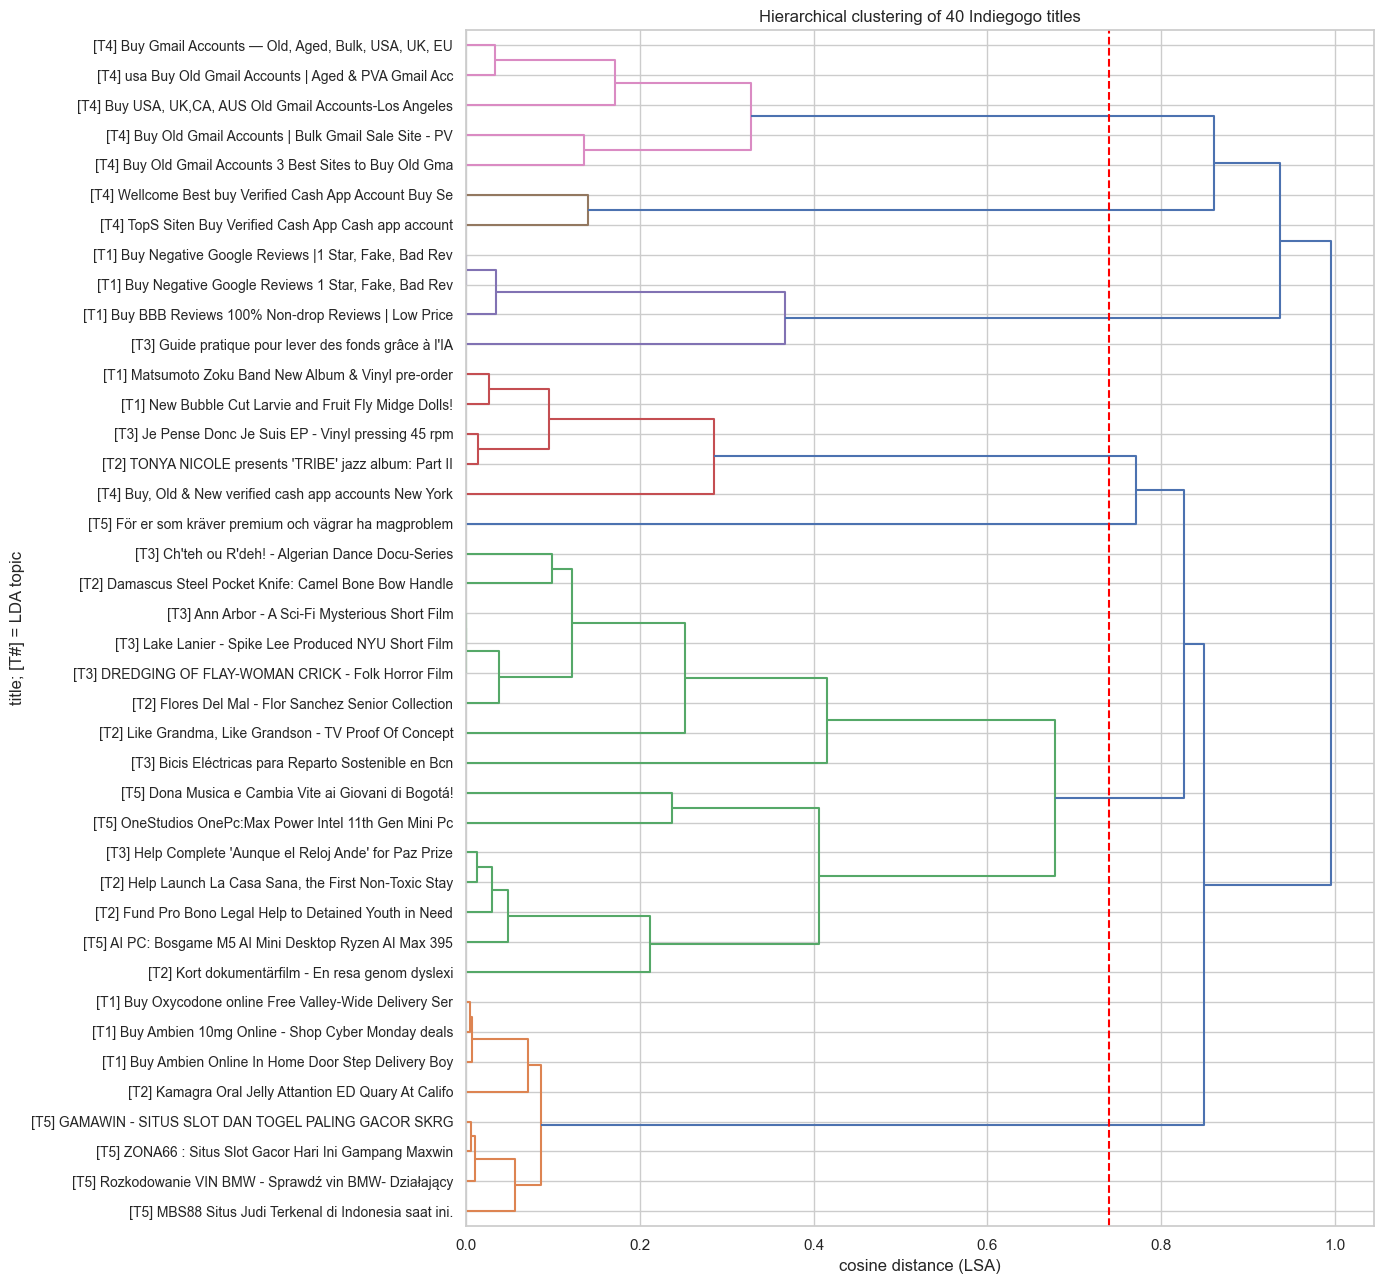

In [112]:
# eight strongest titles from each LDA topic so the tree stays readable
subset = (
    titles.sort_values(['dominant_lda_topic', 'dominant_lda_probability'], ascending=[True, False])
    .groupby('dominant_lda_topic', group_keys=False)
    .head(8)
)
X_subset = X_lsa[subset.index]

# cosine distance in LSA space; average linkage
distance_matrix = cosine_distances(X_subset)
linkage_matrix = linkage(squareform(distance_matrix, checks=False), method='average')

# shorten long titles; [T#] is the LDA topic
leaf_labels = []
for topic, title in zip(subset['dominant_lda_topic'], subset['raw_title']):
    title = ' '.join(str(title).split())
    if len(title) > 54:
        title = title[:53].rstrip() + '...'
    leaf_labels.append(f'[T{topic}] {title}')

CUT_DISTANCE = 0.74  # draw the split here so the tight spam groups separate from the looser film/product titles 

fig, ax = plt.subplots(figsize=(14, 13))
dendrogram(
    linkage_matrix,
    labels=leaf_labels,
    orientation='right',
    leaf_font_size=10,
    color_threshold=CUT_DISTANCE,
    ax=ax,
)
ax.axvline(CUT_DISTANCE, color='red', linestyle='--')
ax.set_title('Hierarchical clustering of 40 Indiegogo titles')
ax.set_xlabel('cosine distance (LSA)')
ax.set_ylabel('title; [T#] = LDA topic')
plt.tight_layout()
plt.show()


## Findings

### Context
Indiegogo is a crowdfunding site. You post a campaign title and ask people for money for a project. 

What I would have expected were titles about campaigning for legitimate projects. 

### Findings
Most of what we got was spam selling Gmail, Cash App, and LinkedIn accounts. 

LSA and LDA both land on that. LSA just cuts the spam into shops. LDA keeps a smaller leftover pile of film and product titles that look more like real campaigns.

- LSA's cleanest clusters are Cash App, Gmail/PVA, LinkedIn, and Google Voice sales.
- LDA dumps most of that same language into Topic 4 (about 9,120 titles).
- LDA Topic 3 is short films. Topic 5 is products and travel.
- On the dendrogram the account-sale branches are tight. The film and product branches are looser.

### Limitations

- A lot of titles are spam or near-dups. we only dropped exact dups, so the clusters describe this dump, not a clean set of real campaigns.
- Titles are short, so the matrix is still about 99.96% sparse.
- 20 LSA components explain 20.30% of variance.
- I picked k = 7 and 5 LDA topics because those were readable. Other settings would change the splits.
